# 06 – Modelling

**Objective:** find out which features really help, compare models, and check that the probabilities can be trusted.

**Key results (walk-forward validation, 17,126 matches from 2015–2021)**
- **Chosen model:** logistic regression, with 68.46% accuracy and a log loss of 0.5856.
- **Comparison:** ATP ranking alone scores 64.55% and 0.6226, and Elo alone scores 67.56% and 0.5971.
- **Calibration:** predictions are generally within about 2 points of what really happened.
- **Still to come:** the final test on matches from 2022 onwards, and the comparison with bookmakers.

In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "../src")
from tennis_elo import win_probability
from tennis_features import FEATURE_GROUPS
from tennis_models import (INTERACTIONS, add_interactions, boosting_model, fit_both_views, logistic_model,
                           recalibrate_walk_forward, score, walk_forward)

CHART_COLOR = "#2a78d6"
TEXT_COLOR = "#52514e"
GRID_COLOR = "#e4e3df"
REFERENCE_COLOR = "#8a8981"

conn = sqlite3.connect(Path("../data/processed/tennis.db"))
data = pd.read_sql_query("SELECT * FROM match_features WHERE tourney_level <> 'D' AND year <= 2021", conn)
data = add_interactions(data)
validation = data["year"].between(2015, 2021)
print(f"{len(data):,} matches loaded, {validation.sum():,} in validation")

59,320 matches loaded, 17,126 in validation


## 1. How the models are tested

**Walk-forward validation** copies real life: to predict 2015, train on 2005–2014. To predict 2016, train on 2005–2015, and so on up to 2021. Every prediction is made by a model that has never seen that year or anything later.

**Both points of view:** each match is used in training twice, once from each player's side, with a target of 1 and 0. This removes the "winner always first" problem. Predictions also average both views, so swapping the two players always gives exactly the opposite probability.

**Test period:** the query above stops at 2021. Matches from 2022 onwards aren't even loaded into this notebook.

## 2. Baselines

In [2]:
rank_probability = walk_forward(data, ["d_log_rank"], logistic_model)

results = [
    {"model": "ATP ranking only", **score(rank_probability[validation])},
    {"model": "Elo only (no model)", **score(win_probability(data.loc[validation, "d_elo_combined"], 0))},
]
pd.DataFrame(results)

,model,accuracy_pct,log_loss
0,ATP ranking only,64.55,0.6226
1,Elo only (no model),67.56,0.5971


## 3. Which features help?

Groups are added one at a time to a logistic regression. The last column shows how much each one lowered the log loss. A group that doesn't lower it isn't really helping, however sensible it sounds.

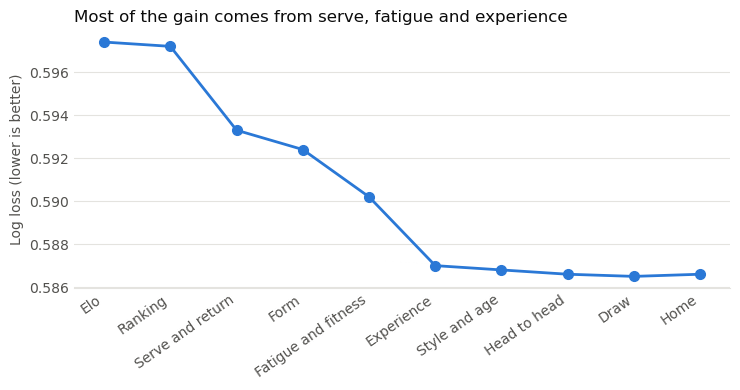

,added_group,accuracy_pct,log_loss,log_loss_improvement
0,Elo,67.62,0.5974,NaN
1,Ranking,67.73,0.5972,0.0002
2,Serve and return,67.95,0.5933,0.0039
3,Form,67.84,0.5924,0.0009
4,Fatigue and fitness,68.03,0.5902,0.0022
5,Experience,68.38,0.5870,0.0032
6,Style and age,68.41,0.5868,0.0002
7,Head to head,68.49,0.5866,0.0002
8,Draw,68.36,0.5865,0.0001
9,Home,68.38,0.5866,-0.0001


In [3]:
ORDER = ["Elo", "Ranking", "Serve and return", "Form", "Fatigue and fitness", "Experience",
         "Style and age", "Head to head", "Draw", "Home"]

rows, columns = [], []
for group in ORDER:
    columns = columns + FEATURE_GROUPS[group]
    p = walk_forward(data, columns, logistic_model)
    rows.append({"added_group": group, **score(p[validation])})

steps = pd.DataFrame(rows)
steps["log_loss_improvement"] = (-steps["log_loss"].diff()).round(4)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(steps["added_group"], steps["log_loss"], color=CHART_COLOR, linewidth=2, marker="o", markersize=7)
ax.set_ylabel("Log loss (lower is better)", color=TEXT_COLOR)
ax.set_title("Most of the gain comes from serve, fatigue and experience", loc="left", fontsize=12, color="#0b0b0b")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color(GRID_COLOR)
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=TEXT_COLOR, length=0)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

steps

## 4. Comparing models

- **Logistic regression:** adds up weighted features. It is simple and easy to explain. Product features give it a few interactions, such as Elo mattering more in best-of-5 matches.
- **Gradient boosting:** combines many small decision trees, and finds interactions by itself.
- **Blend:** the average of the two.

In [4]:
FEATURES = [column for group in ORDER for column in FEATURE_GROUPS[group]]
CONTEXT = FEATURE_GROUPS["Match context"]

logistic_p = walk_forward(data, FEATURES + list(INTERACTIONS), logistic_model)
boosting_p = walk_forward(data, FEATURES + CONTEXT, boosting_model)

comparison = results + [
    {"model": "Logistic regression", **score(logistic_p[validation])},
    {"model": "Gradient boosting", **score(boosting_p[validation])},
    {"model": "Blend of both", **score(((logistic_p + boosting_p) / 2)[validation])},
]
pd.DataFrame(comparison).sort_values("log_loss")

,model,accuracy_pct,log_loss
4,Blend of both,68.14,0.5854
2,Logistic regression,68.46,0.5856
3,Gradient boosting,68.35,0.5881
1,Elo only (no model),67.56,0.5971
0,ATP ranking only,64.55,0.6226


**Finding:** the blend's log loss is 0.0002 better than logistic regression, too small to count as a real difference. Logistic regression is chosen because it is simpler to explain and scores about the same. Gradient boosting doesn't win here: with this much overlap between features and this much randomness in tennis, its extra flexibility adds little.

## 5. Are the probabilities trustworthy?

Points on the dashed line are perfectly calibrated: when the model says 70%, the favourite wins 70% of the time.

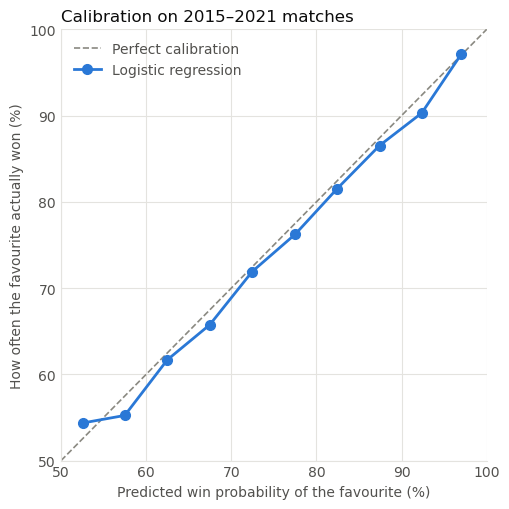

,n_matches,predicted,actual
0,2594,0.525,0.544
1,2417,0.575,0.552
2,2346,0.625,0.617
3,2172,0.675,0.657
4,1980,0.725,0.719
5,1781,0.775,0.762
6,1466,0.824,0.815
7,1106,0.874,0.865
8,845,0.924,0.903
9,419,0.970,0.971


In [5]:
def calibration_table(winner_probability):
    favourite = np.maximum(winner_probability, 1 - winner_probability)
    table = pd.DataFrame({"predicted": favourite, "won": winner_probability > 0.5})
    table["bucket"] = pd.cut(table["predicted"], np.arange(0.5, 1.01, 0.05), include_lowest=True)
    return (
        table.groupby("bucket", observed=True)
        .agg(n_matches=("won", "size"), predicted=("predicted", "mean"), actual=("won", "mean"))
        .reset_index(drop=True)
    )


calibration = calibration_table(logistic_p[validation])

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.plot([50, 100], [50, 100], color=REFERENCE_COLOR, linestyle="--", linewidth=1.2, label="Perfect calibration")
ax.plot(100 * calibration["predicted"], 100 * calibration["actual"], color=CHART_COLOR,
        linewidth=2, marker="o", markersize=7, label="Logistic regression")
ax.set_xlim(50, 100)
ax.set_ylim(50, 100)
ax.set_xlabel("Predicted win probability of the favourite (%)", color=TEXT_COLOR)
ax.set_ylabel("How often the favourite actually won (%)", color=TEXT_COLOR)
ax.set_title("Calibration on 2015–2021 matches", loc="left", fontsize=12, color="#0b0b0b")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color(GRID_COLOR)
ax.grid(color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=TEXT_COLOR, length=0)
ax.legend(frameon=False, labelcolor=TEXT_COLOR, loc="upper left")
plt.tight_layout()
plt.show()

calibration.round(3)

Could a calibration step improve the probabilities further? Each year is corrected using only earlier years' predictions, so 2015 can't be included in this comparison.

In [6]:
corrected = recalibrate_walk_forward(data, logistic_p)
years_2016_on = data["year"].between(2016, 2021)

pd.DataFrame([
    {"version": "Logistic regression", **score(logistic_p[years_2016_on])},
    {"version": "With calibration step", **score(corrected[years_2016_on])},
])

,version,accuracy_pct,log_loss
0,Logistic regression,67.88,0.5908
1,With calibration step,67.88,0.5905


**Finding:** calibration is much better than in notebook 04, and predictions are generally within about 2 points of reality. The extra calibration step improves log loss by only 0.0003, so it isn't needed for this model.

## 6. What does the model rely on?

Each feature was scaled before training, so coefficient sizes can be compared directly. A positive value means that having more of it than the opponent raises a player's chances.

In [7]:
final_columns = FEATURES + list(INTERACTIONS)
model = fit_both_views(logistic_model(), data.loc[data["year"].between(2005, 2021), final_columns])

coefficients = pd.Series(model[-1].coef_[0], index=final_columns).sort_values(key=np.abs, ascending=False)
coefficients.head(12).round(3).rename("coefficient").to_frame()

,coefficient
d_serve_slow,-0.646
d_elo_overall,0.539
d_serve_adj,0.421
d_return_adj,0.350
d_return_slow,-0.341
d_elo_combined,0.334
d_log_career,-0.274
d_serve_fast,0.267
d_log_tour_career,0.265
d_log_surface_career,0.236


**Reading this with care:** many features overlap, such as the three Elo versions or the different form windows. They share credit, so a single coefficient doesn't measure a feature's full importance.

## 7. Conclusions

| Finding | Decision |
|---|---|
| Logistic regression matches more complex models | Use it as the final model |
| Serve and return, experience and fatigue add the most beyond Elo | Keep them |
| Style, head to head and draw information add very little | Harmless, but not where future gains will come from |
| Home advantage adds nothing here, despite the clear effect in notebook 05 | Other features probably already capture much of it |

**Limits of these results**
- **Slightly optimistic:** Elo settings and model choices were made on these same years. The test period will give the honest figure.
- **Not yet a betting result:** a log loss of 0.5856 says nothing about bookmakers until it is compared with their odds on the same matches.
- **Missing information:** this data has no injury news, weather or match-day conditions, which bookmakers can use.